In [1]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [2]:
import kagglehub
import shutil

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")
destination = "/content/plantdisease"
shutil.copytree(path, destination, dirs_exist_ok=True)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease


In [3]:
import os

DATA_DIR = "/content/plantdisease/PlantVillage"

for folder in sorted(os.listdir(DATA_DIR)):
    if folder.startswith("Tomato"):
        print(folder, "=", len(os.listdir(os.path.join(DATA_DIR, folder))), "images")

Tomato_Bacterial_spot = 2127 images
Tomato_Early_blight = 1000 images
Tomato_Late_blight = 1909 images
Tomato_Leaf_Mold = 952 images
Tomato_Septoria_leaf_spot = 1771 images
Tomato_Spider_mites_Two_spotted_spider_mite = 1676 images
Tomato__Target_Spot = 1404 images
Tomato__Tomato_YellowLeaf__Curl_Virus = 3209 images
Tomato__Tomato_mosaic_virus = 373 images
Tomato_healthy = 1591 images


In [4]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [5]:
# transforming the images so that they have the same dimensions
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [6]:
from PIL import Image, UnidentifiedImageError

class TomatoDataset(Dataset):

    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        skipped = 0

        for folder in sorted(os.listdir(root_dir)):
            if not folder.startswith("Tomato"):
                continue
            label = 0 if folder == "Tomato_healthy" else 1
            folder_path = os.path.join(root_dir, folder)

            for filename in sorted(os.listdir(folder_path)):
                image_path = os.path.join(folder_path, filename)
                try:
                    with Image.open(image_path) as img:
                        img.verify()
                    self.images.append((image_path, label))
                except (UnidentifiedImageError, OSError, ValueError):
                    skipped += 1

        print("Valid images:", len(self.images))
        print("Skipped invalid files:", skipped)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_path, label = self.images[index]
        with Image.open(image_path) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

In [7]:
dataset = TomatoDataset(DATA_DIR, transform=transform)

print("Total valid image paths:", len(dataset))

train_labels = [label for _, label in dataset.images]
indices = np.arange(len(dataset))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=train_labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=[train_labels[i] for i in temp_idx]
)

train_loader = DataLoader(
    Subset(dataset, train_idx),
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    Subset(dataset, val_idx),
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    Subset(dataset, test_idx),
    batch_size=32,
    shuffle=False
)

print("Rebuilt all DataLoaders!")

Valid images: 16011
Skipped invalid files: 1
Total valid image paths: 16011
Rebuilt all DataLoaders!


In [8]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

torch.Size([32, 3, 128, 128]) torch.Size([32])


In [9]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            # First convolution
            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            # Second convolution
            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(channels)
        )

    def forward(self, x):
        residual = x
        # Apply convolution transformations
        out = self.block(x)
        out = out + residual

        # Apply activation
        return torch.relu(out)

In [10]:
block = ResidualBlock(channels=32).to(device)

dummy_input = torch.randn(4, 32, 64, 64).to(device)

output = block(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 32, 64, 64])
Output shape: torch.Size([4, 32, 64, 64])


In [16]:
resnet = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),
    ResidualBlock(32),
    ResidualBlock(32),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(32, 2)
).to(device)

In [12]:
images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = resnet(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 2])


In [13]:
train_targets = [dataset.images[i][1] for i in train_idx]

class_counts = np.bincount(train_targets, minlength=2)

class_weights = len(train_targets) / (2 * class_counts)

weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class counts:", class_counts)
print("Class weights:", weights)

Class counts: [ 1114 10093]
Class weights: tensor([5.0301, 0.5552], device='cuda:0')


In [19]:
loss_fn = nn.CrossEntropyLoss(weight=weights)

optimizer = optim.Adam(
    resnet.parameters(),
    lr=0.001
)

In [24]:
epochs = 10

for epoch in range(epochs):
    resnet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = resnet(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total
    resnet.eval()

    val_correct = 0
    val_total = 0
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = resnet(images)
            loss = loss_fn(outputs, labels)
            val_loss += loss.item()
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)
    val_loss /= len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 0.0358 Train Acc: 98.99% Val Loss: 0.0356 Val Acc: 99.63%
Epoch [2/10] Train Loss: 0.0300 Train Acc: 99.16% Val Loss: 0.0416 Val Acc: 99.67%
Epoch [3/10] Train Loss: 0.0286 Train Acc: 99.21% Val Loss: 0.0286 Val Acc: 99.67%
Epoch [4/10] Train Loss: 0.0373 Train Acc: 98.92% Val Loss: 0.0259 Val Acc: 99.67%
Epoch [5/10] Train Loss: 0.0355 Train Acc: 98.96% Val Loss: 0.0254 Val Acc: 99.54%
Epoch [6/10] Train Loss: 0.0231 Train Acc: 99.38% Val Loss: 0.0346 Val Acc: 99.38%
Epoch [7/10] Train Loss: 0.0220 Train Acc: 99.45% Val Loss: 0.0382 Val Acc: 97.25%
Epoch [8/10] Train Loss: 0.0286 Train Acc: 99.30% Val Loss: 0.0489 Val Acc: 96.71%
Epoch [9/10] Train Loss: 0.0363 Train Acc: 99.19% Val Loss: 0.0296 Val Acc: 99.25%
Epoch [10/10] Train Loss: 0.0347 Train Acc: 99.01% Val Loss: 0.0116 Val Acc: 99.67%


In [25]:
resnet.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = resnet(images)
        predictions = outputs.argmax(dim=1)
        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

print("Test samples:", len(y_true))

Test samples: 2402


Classification Report:

              precision    recall  f1-score   support

     Healthy       0.95      1.00      0.97       238
    Diseased       1.00      0.99      1.00      2164

    accuracy                           0.99      2402
   macro avg       0.97      1.00      0.99      2402
weighted avg       0.99      0.99      0.99      2402

Confusion Matrix:



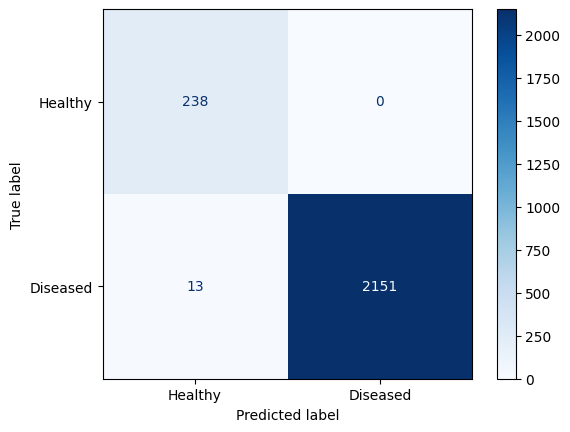

In [28]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=["Healthy", "Diseased"]
))

print("Confusion Matrix:\n")
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy", "Diseased"]
).plot(cmap="Blues")